=== PART 2A: Analytical Kelly Curve (55% Edge, 1:1) ===
Full Kelly f*            : 10.0%  | g(f*)   = +0.005008
Half-Kelly f*/2          : 5.0%  | g(f*/2) = +0.003753
Growth retained at f*/2  : 74.93% of maximum
Zero-growth cliff (g=0)  : ~19.83%



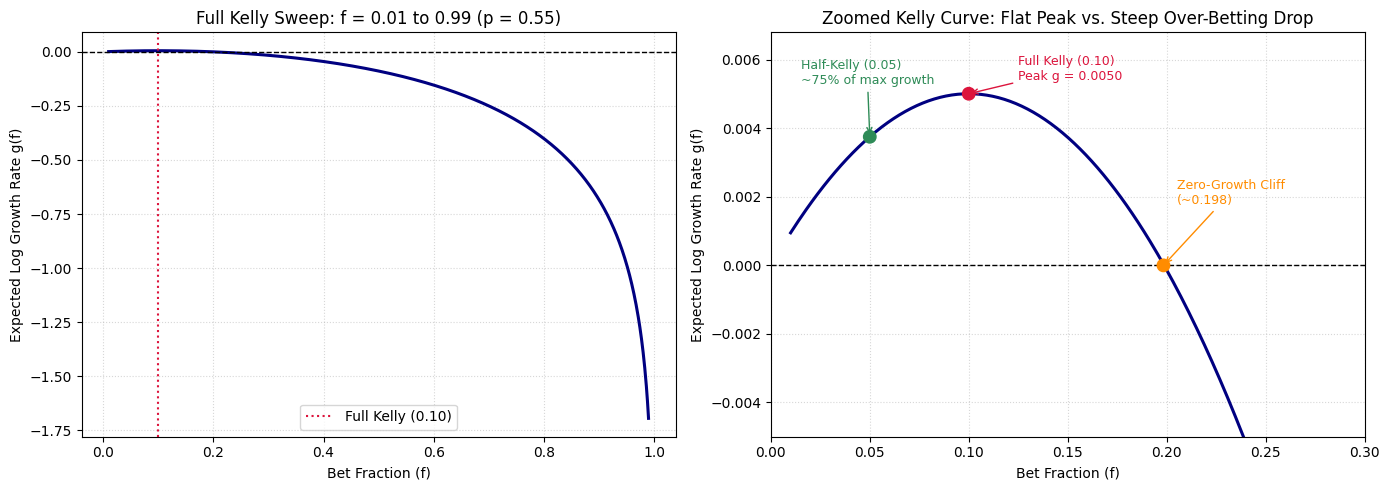

=== PART 2B: Monte Carlo Comparison (p = 0.55, 1,000 Paths x 500 Rounds) ===
Strategy            |  Med W_500 |  % Profit |  Med MaxDD |  % DD>=50%
--------------------------------------------------------------------
Half-Kelly (0.05)   |       7.22 |     95.8% |     -52.6% |      57.7%
Full Kelly (0.10)   |      14.95 |     88.7% |     -82.0% |     100.0%
2x Kelly   (0.20)   |       1.40 |     51.3% |     -99.3% |     100.0%


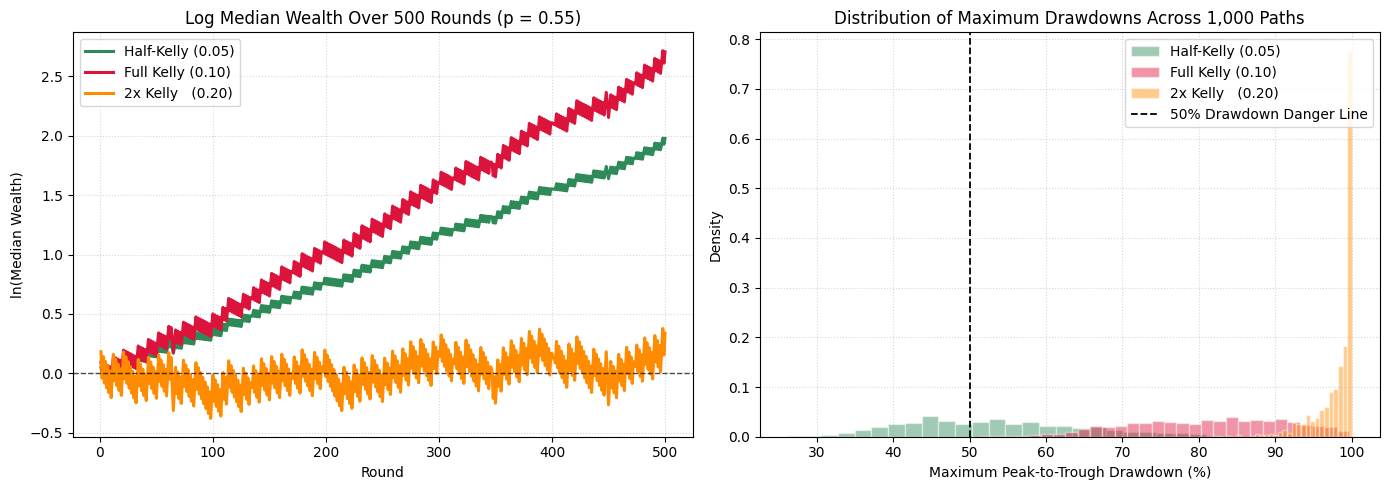


=== PART 3: Overestimated Edge Stress Test (Est p=0.60, True p=0.54) ===
Strategy                   |  True g(f) |  Med W_500 |  % Profit |  % DD>=50%
----------------------------------------------------------------------------
Oracle True Kelly (0.08)   |  +0.003203 |      4.962 |     80.2% |      99.1%
Half-Kelly of Est (0.10)   |  +0.003002 |      4.485 |     75.1% |     100.0%
Full Kelly of Est (0.20)   |  -0.004192 |      0.123 |     30.4% |     100.0%


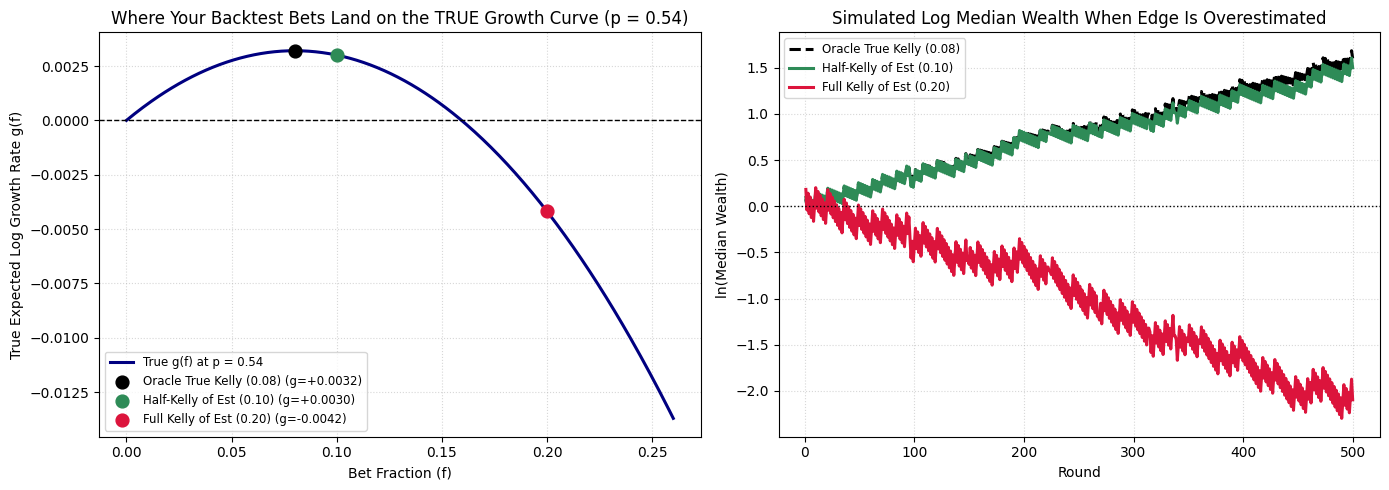

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def log_growth(f, p, b=1.0):
    """Expected 1-round log growth rate g(f) = p*ln(1 + b*f) + (1-p)*ln(1 - f)."""
    q = 1.0 - p
    return p * np.log(1.0 + b * f) + q * np.log(1.0 - f)

# ==========================================================
# PART 2A: Analytical Kelly Curve Sweep (p = 0.55, b = 1.0)
# ==========================================================
p, b = 0.55, 1.0
q = 1.0 - p

f_star = p - q / b          # 0.10 (Full Kelly)
f_half = f_star / 2.0       # 0.05 (Half-Kelly)

f_grid = np.linspace(0.01, 0.99, 1_000)
g_grid = log_growth(f_grid, p, b)

g_star = log_growth(f_star, p, b)
g_half = log_growth(f_half, p, b)

# Locate where g(f) crosses from positive back to zero (Zero-Growth Cliff)
positive_idx = np.where(g_grid > 0)[0]
f_cliff = f_grid[positive_idx[-1]]

print("=== PART 2A: Analytical Kelly Curve (55% Edge, 1:1) ===")
print(f"Full Kelly f*            : {f_star*100:.1f}%  | g(f*)   = {g_star:+.6f}")
print(f"Half-Kelly f*/2          : {f_half*100:.1f}%  | g(f*/2) = {g_half:+.6f}")
print(f"Growth retained at f*/2  : {(g_half / g_star) * 100:.2f}% of maximum")
print(f"Zero-growth cliff (g=0)  : ~{f_cliff*100:.2f}%\n")

# --- PLOT 1: Full Sweep & Zoomed Kelly Curve ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: Full sweep 0.01 to 0.99
ax1.plot(f_grid, g_grid, color='navy', linewidth=2.2)
ax1.axhline(0, color='black', linestyle='--', linewidth=1)
ax1.axvline(f_star, color='crimson', linestyle=':', linewidth=1.5, label=f'Full Kelly ({f_star:.2f})')
ax1.set_title('Full Kelly Sweep: f = 0.01 to 0.99 (p = 0.55)')
ax1.set_xlabel('Bet Fraction (f)')
ax1.set_ylabel('Expected Log Growth Rate g(f)')
ax1.grid(True, linestyle=':', alpha=0.5)
ax1.legend()

# Right: Zoomed view showing flatness near peak & asymmetry
ax2.plot(f_grid, g_grid, color='navy', linewidth=2.2, label='g(f)')
ax2.axhline(0, color='black', linestyle='--', linewidth=1)
ax2.scatter([f_half, f_star, f_cliff],
            [g_half, g_star, 0.0],
            color=['seagreen', 'crimson', 'darkorange'],
            s=80, zorder=5)

ax2.annotate(f'Half-Kelly ({f_half:.2f})\n~75% of max growth',
             xy=(f_half, g_half), xytext=(0.015, 0.0053),
             arrowprops=dict(arrowstyle='->', color='seagreen'), color='seagreen', fontsize=9)
ax2.annotate(f'Full Kelly ({f_star:.2f})\nPeak g = {g_star:.4f}',
             xy=(f_star, g_star), xytext=(0.125, 0.0054),
             arrowprops=dict(arrowstyle='->', color='crimson'), color='crimson', fontsize=9)
ax2.annotate(f'Zero-Growth Cliff\n(~{f_cliff:.3f})',
             xy=(f_cliff, 0.0), xytext=(0.205, 0.0018),
             arrowprops=dict(arrowstyle='->', color='darkorange'), color='darkorange', fontsize=9)

ax2.set_xlim(0.0, 0.30)
ax2.set_ylim(-0.005, 0.0068)
ax2.set_title('Zoomed Kelly Curve: Flat Peak vs. Steep Over-Betting Drop')
ax2.set_xlabel('Bet Fraction (f)')
ax2.set_ylabel('Expected Log Growth Rate g(f)')
ax2.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

# ==========================================================
# PART 2B: Monte Carlo — Half-Kelly vs Full Kelly vs 2x Kelly
# ==========================================================
rng = np.random.default_rng(seed=42)
n_paths = 1_000
n_rounds = 500
rounds = np.arange(1, n_rounds + 1)

wins_55 = rng.random(size=(n_paths, n_rounds)) < p

strategies = [
    ('Half-Kelly (0.05)', f_half, 'seagreen'),
    ('Full Kelly (0.10)', f_star, 'crimson'),
    ('2x Kelly   (0.20)', 2 * f_star, 'darkorange')
]

print("=== PART 2B: Monte Carlo Comparison (p = 0.55, 1,000 Paths x 500 Rounds) ===")
print(f"{'Strategy':<19} | {'Med W_500':>10} | {'% Profit':>9} | {'Med MaxDD':>10} | {'% DD>=50%':>10}")
print("-" * 68)

# --- PLOT 2: Log Median Wealth & Max Drawdown Comparison ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

dd_data = []
dd_labels = []
dd_colors = []

for label, f, color in strategies:
    mult = np.where(wins_55, 1.0 + f, 1.0 - f)
    W = np.cumprod(mult, axis=1, dtype=np.float64)

    log_med_W = np.log(np.median(W, axis=0))
    med_w_500 = np.median(W[:, -1])
    pct_profit = np.mean(W[:, -1] > 1.0) * 100

    running_peak = np.maximum(1.0, np.maximum.accumulate(W, axis=1))
    drawdown = (W - running_peak) / running_peak
    max_dd = drawdown.min(axis=1)

    med_max_dd = np.median(max_dd) * 100
    pct_dd50 = np.mean(max_dd <= -0.50) * 100

    print(f"{label:<19} | {med_w_500:10.2f} | {pct_profit:8.1f}% | {med_max_dd:9.1f}% | {pct_dd50:9.1f}%")

    ax1.plot(rounds, log_med_W, color=color, linewidth=2.2, label=label)
    dd_data.append(-max_dd * 100)  # Positive % drawdown magnitude for cleaner histogram
    dd_labels.append(label)
    dd_colors.append(color)

ax1.axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.7)
ax1.set_title('Log Median Wealth Over 500 Rounds (p = 0.55)')
ax1.set_xlabel('Round')
ax1.set_ylabel('ln(Median Wealth)')
ax1.grid(True, linestyle=':', alpha=0.5)
ax1.legend()

# Right: Distribution of worst peak-to-trough drawdowns
for data, label, color in zip(dd_data, dd_labels, dd_colors):
    ax2.hist(data, bins=30, alpha=0.45, color=color, edgecolor='white', label=label, density=True)

ax2.axvline(50, color='black', linestyle='--', linewidth=1.3, label='50% Drawdown Danger Line')
ax2.set_title('Distribution of Maximum Drawdowns Across 1,000 Paths')
ax2.set_xlabel('Maximum Peak-to-Trough Drawdown (%)')
ax2.set_ylabel('Density')
ax2.grid(True, linestyle=':', alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()

# ==========================================================
# PART 3: Break-It Stress Test — Overestimated Edge Penalty
# Backtest says p_hat = 0.60 (f_hat* = 0.20, half = 0.10)
# Live reality is p_true = 0.54 (true f* = 0.08)
# ==========================================================
p_est = 0.60
p_true = 0.54

f_oracle = p_true - (1 - p_true)   # 0.08 (True Kelly)
f_est_half = (p_est - (1 - p_est)) / 2.0  # 0.10 (Half-Kelly of wrong backtest)
f_est_full = p_est - (1 - p_est)          # 0.20 (Full Kelly of wrong backtest)

wins_54 = rng.random(size=(n_paths, n_rounds)) < p_true

stress_strats = [
    ('Oracle True Kelly (0.08)', f_oracle, 'black', '--'),
    ('Half-Kelly of Est (0.10)', f_est_half, 'seagreen', '-'),
    ('Full Kelly of Est (0.20)', f_est_full, 'crimson', '-')
]

print("\n=== PART 3: Overestimated Edge Stress Test (Est p=0.60, True p=0.54) ===")
print(f"{'Strategy':<26} | {'True g(f)':>10} | {'Med W_500':>10} | {'% Profit':>9} | {'% DD>=50%':>10}")
print("-" * 76)

# --- PLOT 3: True g(f) Curve & Over-Betting Collapse ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: True g(f) curve for p_true = 0.54 with all 3 bet sizes marked
f_zoom = np.linspace(0.0, 0.26, 400)
ax1.plot(f_zoom, log_growth(f_zoom, p_true), color='navy', linewidth=2.2, label='True g(f) at p = 0.54')
ax1.axhline(0, color='black', linestyle='--', linewidth=1)

for label, f, color, ls in stress_strats:
    g_true_val = log_growth(f, p_true)
    ax1.scatter([f], [g_true_val], color=color, s=85, zorder=5, label=f'{label} (g={g_true_val:+.4f})')

    mult = np.where(wins_54, 1.0 + f, 1.0 - f)
    W = np.cumprod(mult, axis=1, dtype=np.float64)

    log_med_W = np.log(np.median(W, axis=0))
    med_w_500 = np.median(W[:, -1])
    pct_profit = np.mean(W[:, -1] > 1.0) * 100

    running_peak = np.maximum(1.0, np.maximum.accumulate(W, axis=1))
    max_dd = ((W - running_peak) / running_peak).min(axis=1)
    pct_dd50 = np.mean(max_dd <= -0.50) * 100

    print(f"{label:<26} | {g_true_val:+10.6f} | {med_w_500:10.3f} | {pct_profit:8.1f}% | {pct_dd50:9.1f}%")
    ax2.plot(rounds, log_med_W, color=color, linestyle=ls, linewidth=2.2, label=label)

ax1.set_title('Where Your Backtest Bets Land on the TRUE Growth Curve (p = 0.54)')
ax1.set_xlabel('Bet Fraction (f)')
ax1.set_ylabel('True Expected Log Growth Rate g(f)')
ax1.grid(True, linestyle=':', alpha=0.5)
ax1.legend(fontsize=8.5)

ax2.axhline(0, color='black', linestyle=':', linewidth=1)
ax2.set_title('Simulated Log Median Wealth When Edge Is Overestimated')
ax2.set_xlabel('Round')
ax2.set_ylabel('ln(Median Wealth)')
ax2.grid(True, linestyle=':', alpha=0.5)
ax2.legend(fontsize=8.5)

plt.tight_layout()
plt.show()
